# Stock-out Risk: CatBoost vs XGBoost vs LightGBM

Prediksi **item mana yang akan kehabisan stok** per outlet, memakai dataset turunan `ML/data/stock_forecast_dataset.csv` yang dibangun oleh `ML/script/build_stock_dataset.py`.

Target utama: `Y_empty_lead` — `ClosingStock` menyentuh 0 dalam lead time outlet tersebut (SHOP001 = 3 hari, SHOP002/003 = 2 hari). Tiga target lain diuji sebagai pembanding.

Kenapa bukan model `stock_prediction` yang sudah ada: artefak itu hanya memakai kalender dan lag permintaan, tanpa level stok maupun order yang sedang jalan, dan labelnya proxy "permintaan lebih cepat dari biasanya" (`roc_auc` 0.5348 di metadata). Pertanyaan "stok mana yang akan kurang" tidak bisa dijawab tanpa fitur stok.

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)

DATA_DIR = next(p for p in [Path.cwd() / "../data", Path.cwd() / "ML/data"] if (p / "stock_forecast_dataset.csv").exists())
frame = pd.read_csv(DATA_DIR / "stock_forecast_dataset.csv", parse_dates=["Date"])
meta = json.loads((DATA_DIR / "stock_forecast_dataset_meta.json").read_text())

FEATURES = meta["features"]
CATEGORICAL = meta["feature_groups"]["categorical"]
STOCK_STATE = meta["feature_groups"]["stock_state"]
DEMAND = meta["feature_groups"]["demand"]
TARGET = "Y_empty_lead"
HORIZONS = ["Y_empty_2", "Y_empty_3", "Y_empty_7", "Y_empty_lead", "Y_belowmin_3"]
LEAD_DAYS = meta["lead_days"]

for column in CATEGORICAL:
    frame[column] = frame[column].astype("category")

train = frame[frame.split == "train"].reset_index(drop=True)
test = frame[frame.split == "test"].reset_index(drop=True)
print(f"dataset {len(frame):,} baris | {frame.Outlet.nunique()} outlet x {frame.ItemID.nunique()} item | "
      f"train {len(train):,} s.d. {train.Date.max():%Y-%m-%d} | test {len(test):,} {test.Date.min():%Y-%m-%d}..{test.Date.max():%Y-%m-%d}")
print(f"fitur {len(FEATURES)} + {len(CATEGORICAL)} categorical | lead time {LEAD_DAYS}")

dataset 66,834 baris | 3 outlet x 94 item | train 60,348 s.d. 2025-08-31 | test 6,486 2025-09-01..2025-09-23
fitur 29 + 2 categorical | lead time {'SHOP001': 3, 'SHOP002': 2, 'SHOP003': 2}


## Label dan kualitas data

Base rate tiap label dipisah train/test. `Y_empty_lead` dipakai sebagai target utama karena horizonnya mengikuti lead time: kalau item kosong sebelum order berikutnya tiba, itu kejadian yang harus dicegah sekarang.

`Y_belowmin_3` sengaja dipertahankan sebagai pembanding: base rate-nya jauh lebih tinggi, jadi metriknya terlihat bagus padahal pertanyaannya lebih mudah.

In [2]:
rates = pd.DataFrame({
    "train": [train[label].mean() for label in HORIZONS],
    "test": [test[label].mean() for label in HORIZONS],
}, index=HORIZONS).round(3)
rates["positif train"] = (rates.train * len(train)).astype(int)
rates["positif test"] = (rates.test * len(test)).astype(int)
print("base rate label:")
print(rates.to_string())

print()
print("distribusi days_to_empty (hari sampai stok 0, dibatasi 14):")
print(frame.days_to_empty.value_counts(dropna=False).sort_index().head(8).to_string())
print(f"median {frame.days_to_empty.median():.0f} hari | {frame.days_to_empty.le(3).mean():.1%} baris kosong dalam <=3 hari")

print()
print("censoring: "
      f"{frame.is_censored.mean():.2%} baris terpotong, {int(frame.lost_units.sum()):,} unit hilang, "
      f"fill rate {frame.StockOut.sum() / frame.demand_true.sum():.2%}")

base rate label:
              train   test  positif train  positif test
Y_empty_2     0.103  0.081           6215           525
Y_empty_3     0.146  0.114           8810           739
Y_empty_7     0.286  0.223          17259          1446
Y_empty_lead  0.122  0.096           7362           622
Y_belowmin_3  0.355  0.314          21423          2036

distribusi days_to_empty (hari sampai stok 0, dibatasi 14):
days_to_empty
1.0    3910
2.0    2858
3.0    2762
4.0    2607
5.0    2387
6.0    2188
7.0    2010
8.0    1832
median 6 hari | 14.3% baris kosong dalam <=3 hari

censoring: 2.27% baris terpotong, 2,203 unit hilang, fill rate 95.97%


In [3]:
by_outlet = pd.DataFrame({
    "base_rate": frame.groupby("Outlet", observed=True)[TARGET].mean(),
    "rows": frame.groupby("Outlet", observed=True)[TARGET].size(),
    "median_cover_days": frame.groupby("Outlet", observed=True).cover_days.median(),
    "median_on_order": frame.groupby("Outlet", observed=True).on_order_qty.median(),
}).round(3)
by_outlet["lead_days"] = by_outlet.index.map(LEAD_DAYS)
by_outlet

,base_rate,rows,median_cover_days,median_on_order,lead_days
Outlet,,,,,
SHOP001,0.189,22278,4.9,0.0,3
SHOP002,0.080,22278,7.0,0.0,2
SHOP003,0.089,22278,5.6,0.0,2


## Baseline tanpa model

Dua aturan deterministik, keduanya hanya memakai informasi yang tersedia hari ini:

- `cover_days < lead_days` — stok tidak cukup untuk menutup lead time pada laju jual 7 hari terakhir.
- `gap_to_reorder_dyn < 0` — stok ditambah order yang sedang jalan di bawah reorder point adaptif.

Kalau model tidak mengalahkan ini, modelnya tidak berguna.

In [4]:
def binary_metrics(actual, flag, score) -> dict:
    return {
        "precision": precision_score(actual, flag, zero_division=0),
        "recall": recall_score(actual, flag, zero_division=0),
        "f1": f1_score(actual, flag, zero_division=0),
        "pr_auc": average_precision_score(actual, score),
    }


y_test = test[TARGET].to_numpy()
baselines = {
    "rule: cover_days < lead": binary_metrics(y_test, (test.cover_days < test.Outlet.map(LEAD_DAYS)).astype(int).to_numpy(), -test.cover_days.to_numpy()),
    "rule: gap_to_reorder < 0": binary_metrics(y_test, (test.gap_to_reorder_dyn < 0).astype(int).to_numpy(), -test.gap_to_reorder_dyn.to_numpy()),
}
pd.DataFrame(baselines).T.round(3)

,precision,recall,f1,pr_auc
rule: cover_days < lead,0.267,0.407,0.322,0.218
rule: gap_to_reorder < 0,0.224,0.320,0.264,0.173


## Model

CatBoost, XGBoost, dan LightGBM dengan konfigurasi setara (400 iterasi, learning rate 0.05, depth 6 / 31 leaves). Tanpa `class_weight` dan tanpa SMOTE: imbalance ditangani lewat pemilihan threshold, bukan resampling yang mengubah kalibrasi.

Perbandingan memakai **rolling-origin cross-validation 3 fold** pada data train (expanding window, validasi 28 hari). Satu split saja tidak cukup: selisih antar model di data ini kecil dan bisa jadi kebetulan satu periode.

In [5]:
FOLDS = [
    ("2025-06-01", "2025-06-28"),
    ("2025-07-01", "2025-07-28"),
    ("2025-08-01", "2025-08-28"),
]

MODELS = {
    "CatBoost": lambda: CatBoostClassifier(iterations=400, learning_rate=0.05, depth=6, cat_features=CATEGORICAL,
                                           verbose=0, random_seed=42, thread_count=-1, allow_writing_files=False),
    "XGBoost": lambda: XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=6, enable_categorical=True,
                                     tree_method="hist", n_jobs=-1, random_state=42, eval_metric="logloss"),
    "LightGBM": lambda: LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31, verbose=-1,
                                       n_jobs=-1, random_state=42),
}


def cross_validate(target: str, features: list[str]) -> dict:
    scores = {name: {"folds": [], "oof": []} for name in MODELS}
    for start, end in FOLDS:
        start, end = pd.Timestamp(start), pd.Timestamp(end)
        fit = train[train.Date < start]
        validate = train[(train.Date >= start) & (train.Date <= end)]
        if validate.empty:
            continue
        for name, factory in MODELS.items():
            model = factory().fit(fit[features + CATEGORICAL], fit[target])
            probability = model.predict_proba(validate[features + CATEGORICAL])[:, 1]
            scores[name]["folds"].append(average_precision_score(validate[target], probability))
            scores[name]["oof"].append(pd.DataFrame({"actual": validate[target].to_numpy(), "probability": probability,
                                                     "Outlet": validate.Outlet.to_numpy()}))
    return scores


def summarise(scores: dict) -> pd.DataFrame:
    rows = {}
    for name, result in scores.items():
        oof = pd.concat(result["oof"])
        rows[name] = {
            "pr_auc_fold_mean": np.mean(result["folds"]),
            "pr_auc_fold_std": np.std(result["folds"]),
            "pr_auc_pooled": average_precision_score(oof.actual, oof.probability),
            "roc_auc_pooled": roc_auc_score(oof.actual, oof.probability),
        }
    return pd.DataFrame(rows).T.sort_values("pr_auc_pooled", ascending=False)


cv_primary = cross_validate(TARGET, FEATURES)
cv_table = summarise(cv_primary).round(4)
print("target:", TARGET)
cv_table

target: Y_empty_lead


,pr_auc_fold_mean,pr_auc_fold_std,pr_auc_pooled,roc_auc_pooled
CatBoost,0.6902,0.0213,0.6889,0.9197
LightGBM,0.6524,0.0152,0.6501,0.9070
XGBoost,0.6411,0.0147,0.6400,0.9032


In [6]:
horizon_rows = {}
for target in HORIZONS:
    scores = cross_validate(target, FEATURES) if target != TARGET else cv_primary
    for name, result in scores.items():
        oof = pd.concat(result["oof"])
        horizon_rows[(target, name)] = average_precision_score(oof.actual, oof.probability)

horizon_table = pd.Series(horizon_rows).unstack().round(4)
horizon_table.index.name = "target"
horizon_table

,CatBoost,LightGBM,XGBoost
target,,,
Y_belowmin_3,0.8915,0.8796,0.8785
Y_empty_2,0.6945,0.6545,0.6500
Y_empty_3,0.6583,0.6211,0.6085
Y_empty_7,0.6439,0.6173,0.6103
Y_empty_lead,0.6889,0.6501,0.6400


## Threshold

Threshold dipilih dari prediksi out-of-fold CV, bukan dari test. Fungsi biaya memakai asumsi kehabisan stok 5x lebih mahal daripada stok berlebih — ganti angkanya kalau asumsi bisnismu berbeda.

In [7]:
COST_FALSE_NEGATIVE = 5.0
COST_FALSE_POSITIVE = 1.0


def pick_threshold(actual, probability) -> tuple[float, pd.DataFrame]:
    rows = []
    for threshold in np.arange(0.05, 0.96, 0.01):
        flag = (probability >= threshold).astype(int)
        false_negative = int(((flag == 0) & (actual == 1)).sum())
        false_positive = int(((flag == 1) & (actual == 0)).sum())
        rows.append({
            "threshold": round(float(threshold), 2),
            "precision": precision_score(actual, flag, zero_division=0),
            "recall": recall_score(actual, flag, zero_division=0),
            "f1": f1_score(actual, flag, zero_division=0),
            "flagged": int(flag.sum()),
            "cost_per_row": (COST_FALSE_NEGATIVE * false_negative + COST_FALSE_POSITIVE * false_positive) / len(actual),
        })
    sweep = pd.DataFrame(rows)
    best = sweep.loc[sweep.cost_per_row.idxmin()]
    return float(best.threshold), sweep


best_name = cv_table.index[0]
oof_primary = pd.concat(cv_primary[best_name]["oof"])
chosen_threshold, sweep = pick_threshold(oof_primary.actual.to_numpy(), oof_primary.probability.to_numpy())

print(f"model terbaik (CV pooled PR-AUC): {best_name}")
print(f"threshold terpilih (biaya minimum di OOF): {chosen_threshold:.2f}")
sweep.set_index("threshold").loc[[0.2, 0.3, 0.4, 0.5, 0.6, chosen_threshold]].round(3)

model terbaik (CV pooled PR-AUC): CatBoost
threshold terpilih (biaya minimum di OOF): 0.13


,precision,recall,f1,flagged,cost_per_row
threshold,,,,,
0.20,0.483,0.798,0.601,5664,0.270
0.30,0.564,0.675,0.615,4096,0.310
0.40,0.641,0.556,0.595,2970,0.366
0.50,0.714,0.439,0.544,2105,0.431
0.60,0.793,0.338,0.474,1457,0.492
0.13,0.412,0.888,0.563,7372,0.264


## Evaluasi di test

Model dilatih ulang pada seluruh train, lalu diskor sekali di test dengan threshold yang sudah dipilih dari CV. Test tidak dipakai untuk memilih model maupun threshold.

In [8]:
fitted = {}
test_rows = {}
for name, factory in MODELS.items():
    started = time.perf_counter()
    model = factory().fit(train[FEATURES + CATEGORICAL], train[TARGET])
    elapsed = time.perf_counter() - started
    probability = model.predict_proba(test[FEATURES + CATEGORICAL])[:, 1]
    flag = (probability >= chosen_threshold).astype(int)
    fitted[name] = model
    test_rows[name] = {
        "precision": precision_score(y_test, flag, zero_division=0),
        "recall": recall_score(y_test, flag, zero_division=0),
        "f1": f1_score(y_test, flag, zero_division=0),
        "pr_auc": average_precision_score(y_test, probability),
        "roc_auc": roc_auc_score(y_test, probability),
        "brier": brier_score_loss(y_test, probability),
        "flagged_rows": int(flag.sum()),
        "train_seconds": elapsed,
        "probability": probability,
        "flag": flag,
    }

result_table = pd.DataFrame({name: {k: v for k, v in row.items() if k not in ("probability", "flag")}
                             for name, row in test_rows.items()}).T
result_table["precision"] = result_table.precision.round(3)
result_table["recall"] = result_table.recall.round(3)
result_table["f1"] = result_table.f1.round(3)
result_table["pr_auc"] = result_table.pr_auc.round(4)
result_table["roc_auc"] = result_table.roc_auc.round(4)
result_table["brier"] = result_table.brier.round(4)
result_table["train_seconds"] = result_table.train_seconds.round(2)
print(f"threshold {chosen_threshold:.2f} | base rate test {y_test.mean():.3f}")
result_table.sort_values("pr_auc", ascending=False)

threshold 0.13 | base rate test 0.096


,precision,recall,f1,pr_auc,roc_auc,brier,flagged_rows,train_seconds
CatBoost,0.364,0.915,0.521,0.6742,0.9434,0.0505,1562.0,4.98
LightGBM,0.389,0.862,0.536,0.6442,0.9352,0.0532,1379.0,1.03
XGBoost,0.381,0.854,0.527,0.6242,0.9315,0.0550,1394.0,1.14


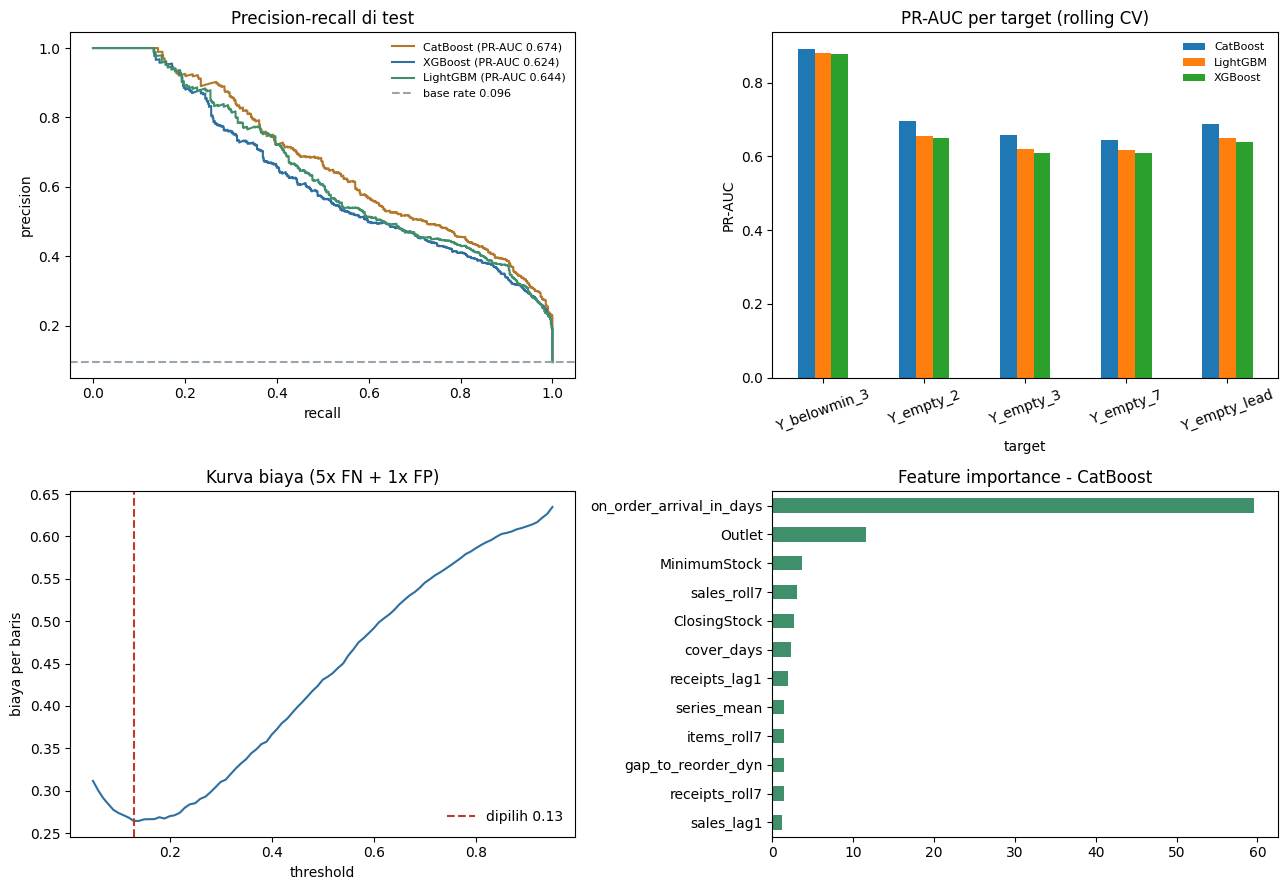

In [9]:
best_probability = test_rows[best_name]["probability"]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
colors = {"CatBoost": "#b4762a", "XGBoost": "#2f6f9f", "LightGBM": "#3f8f6b"}

for name, row in test_rows.items():
    precision, recall, _ = precision_recall_curve(y_test, row["probability"])
    axes[0, 0].plot(recall, precision, label=f"{name} (PR-AUC {row['pr_auc']:.3f})", color=colors[name])
axes[0, 0].axhline(y_test.mean(), color="#9aa5b1", linestyle="--", label=f"base rate {y_test.mean():.3f}")
axes[0, 0].set_xlabel("recall")
axes[0, 0].set_ylabel("precision")
axes[0, 0].set_title("Precision-recall di test")
axes[0, 0].legend(frameon=False, fontsize=8)

horizon_table.plot.bar(ax=axes[0, 1], rot=20)
axes[0, 1].set_title("PR-AUC per target (rolling CV)")
axes[0, 1].set_ylabel("PR-AUC")
axes[0, 1].legend(frameon=False, fontsize=8)

axes[1, 0].plot(sweep.threshold, sweep.cost_per_row, color="#2f6f9f")
axes[1, 0].axvline(chosen_threshold, color="#c0392b", linestyle="--", label=f"dipilih {chosen_threshold:.2f}")
axes[1, 0].set_xlabel("threshold")
axes[1, 0].set_ylabel("biaya per baris")
axes[1, 0].set_title(f"Kurva biaya ({COST_FALSE_NEGATIVE:.0f}x FN + {COST_FALSE_POSITIVE:.0f}x FP)")
axes[1, 0].legend(frameon=False)

importance = pd.Series(fitted[best_name].feature_importances_, index=FEATURES + CATEGORICAL).sort_values()
importance.tail(12).plot.barh(ax=axes[1, 1], color="#3f8f6b")
axes[1, 1].set_title(f"Feature importance - {best_name}")

fig.tight_layout()
plt.show()

## Apakah fitur stok yang menambah nilai

Ablation dengan model yang sama: seluruh fitur, hanya fitur permintaan + traffic + kalender (tanpa level stok dan on-order), lalu hanya fitur stok. Ini yang membuktikan dataset baru memang memperbaiki akurasi, bukan cuma menambah kolom.

`on_order_arrival_in_days` dipisah sendiri karena dominasinya jangan sampai menyesatkan: di ledger ini jadwal kedatangan order sudah pasti, jadi "ada order datang dalam lead time" hampir selalu berarti stok tidak akan habis. Baris **tanpa jadwal order** menguji apakah model masih berguna kalau jadwal itu tidak tersedia.


In [10]:
DEMAND_ONLY = [c for c in FEATURES if c not in STOCK_STATE]
ORDER_SCHEDULE = ["on_order_qty", "on_order_arrival_in_days"]
NO_SCHEDULE = [c for c in FEATURES if c not in ORDER_SCHEDULE]
ablation_rows = {}
for label, columns in [
    ("semua fitur", FEATURES),
    ("tanpa fitur stok", DEMAND_ONLY),
    ("hanya fitur stok", STOCK_STATE),
    ("tanpa jadwal order", NO_SCHEDULE),
]:
    scores = cross_validate(TARGET, columns)
    for name, result in scores.items():
        oof = pd.concat(result["oof"])
        ablation_rows[(label, name)] = average_precision_score(oof.actual, oof.probability)

ablation = pd.Series(ablation_rows).unstack().round(4)
ablation.index.name = "fitur"
ablation

,CatBoost,LightGBM,XGBoost
fitur,,,
hanya fitur stok,0.6940,0.6565,0.6500
semua fitur,0.6889,0.6501,0.6400
tanpa fitur stok,0.3177,0.2863,0.2682
tanpa jadwal order,0.5380,0.4620,0.4395


## Di mana model paling berguna

In [11]:
evaluation = test[["Date", "Outlet", "ItemID", "ClosingStock", "MinimumStock", "on_order_qty", TARGET]].copy()
evaluation["probability"] = best_probability
evaluation["flagged"] = test_rows[best_name]["flag"]

per_outlet = evaluation.groupby("Outlet", observed=True).apply(
    lambda g: pd.Series({
        "rows": len(g),
        "actual_empty": int(g[TARGET].sum()),
        "flagged": int(g.flagged.sum()),
        "precision": precision_score(g[TARGET], g.flagged, zero_division=0),
        "recall": recall_score(g[TARGET], g.flagged, zero_division=0),
        "pr_auc": average_precision_score(g[TARGET], g.probability),
    }),
    include_groups=False,
).round(3)

top_items = (
    evaluation[evaluation.flagged == 1]
    .groupby(["Outlet", "ItemID"], observed=True)
    .agg(flagged_days=("flagged", "size"), actual_empty_days=(TARGET, "sum"), mean_probability=("probability", "mean"))
    .sort_values("flagged_days", ascending=False)
    .head(10)
    .round(3)
)
print("per outlet:"); print(per_outlet.to_string())
print(); print("10 item paling sering ditandai berisiko:"); print(top_items.to_string())

per outlet:
           rows  actual_empty  flagged  precision  recall  pr_auc
Outlet                                                           
SHOP001  2162.0         337.0    748.0      0.425   0.944   0.748
SHOP002  2162.0         112.0    335.0      0.287   0.857   0.556
SHOP003  2162.0         173.0    479.0      0.324   0.896   0.583

10 item paling sering ditandai berisiko:
                flagged_days  actual_empty_days  mean_probability
Outlet  ItemID                                                   
SHOP001 P051              19               14.0             0.574
        P014              18               11.0             0.467
        P041              18               15.0             0.696
        P093              17                8.0             0.724
        P060              16                7.0             0.533
SHOP003 P047              16                8.0             0.567
SHOP001 P024              15                9.0             0.413
        P002          

## Kesimpulan

Sel berikut mencetak ringkasan dari hasil di atas.

In [12]:
best_row = result_table.loc[best_name]
baseline_f1 = max(row["f1"] for row in baselines.values())
baseline_pr = max(row["pr_auc"] for row in baselines.values())
stock_gain = ablation.loc["semua fitur", best_name] - ablation.loc["tanpa fitur stok", best_name]
schedule_gain = ablation.loc["semua fitur", best_name] - ablation.loc["tanpa jadwal order", best_name]

print(f"target            : {TARGET} (stok habis dalam lead time, base rate test {y_test.mean():.3f})")
print(f"model terbaik     : {best_name} - PR-AUC {best_row.pr_auc:.3f}, F1 {best_row.f1:.3f} pada threshold {chosen_threshold:.2f}")
print(f"vs baseline rule  : F1 {baseline_f1:.3f}, PR-AUC {baseline_pr:.3f}")
print(f"tanpa fitur stok  : PR-AUC {ablation.loc['tanpa fitur stok', best_name]:.3f} (tambah {stock_gain:+.3f} dengan fitur stok)")
print(f"tanpa jadwal order: PR-AUC {ablation.loc['tanpa jadwal order', best_name]:.3f} (jadwal order menyumbang {schedule_gain:+.3f})")
print(f"beban alert       : {int(best_row.flagged_rows):,} dari {len(test):,} baris ditandai, {int(y_test.sum()):,} benar-benar kosong")
print()
print("Catatan:")
print("- Ledger sumber deterministik dengan kebijakan (s,S) tetap, jadi sebagian sinyal 'akan habis' bersifat mekanis.")
print("  Di data nyata dengan lead time bervariasi, PR-AUC akan lebih rendah.")
print("- Fitur permintaan memakai StockOut tercatat, yang terpotong saat stok habis; 2.3% baris kehilangan penjualan.")
print("  Untuk item yang sering kosong, permintaan sebenarnya lebih tinggi dari yang dilihat model.")
print("- on_order_qty dan on_order_arrival_in_days direkonstruksi dari pola kedatangan dengan lead time tetap per outlet.")


target            : Y_empty_lead (stok habis dalam lead time, base rate test 0.096)
model terbaik     : CatBoost - PR-AUC 0.674, F1 0.521 pada threshold 0.13
vs baseline rule  : F1 0.322, PR-AUC 0.218
tanpa fitur stok  : PR-AUC 0.318 (tambah +0.371 dengan fitur stok)
tanpa jadwal order: PR-AUC 0.538 (jadwal order menyumbang +0.151)
beban alert       : 1,562 dari 6,486 baris ditandai, 622 benar-benar kosong

Catatan:
- Ledger sumber deterministik dengan kebijakan (s,S) tetap, jadi sebagian sinyal 'akan habis' bersifat mekanis.
  Di data nyata dengan lead time bervariasi, PR-AUC akan lebih rendah.
- Fitur permintaan memakai StockOut tercatat, yang terpotong saat stok habis; 2.3% baris kehilangan penjualan.
  Untuk item yang sering kosong, permintaan sebenarnya lebih tinggi dari yang dilihat model.
- on_order_qty dan on_order_arrival_in_days direkonstruksi dari pola kedatangan dengan lead time tetap per outlet.
